In [1]:
import os
from pathlib import Path
from typing import Literal, Optional, List
import yaml

import numpy as np
import math
import uproot as uproot
import pickle
import pandas as pd
import awkward as ak
from dataclasses import dataclass, field

import matplotlib.pyplot as plt
plt.rcParams.update({"figure.facecolor": "white", "axes.facecolor": "white"})
import matplotlib.colors
from matplotlib.colors import LinearSegmentedColormap
from matplotlib import ticker
from matplotlib.ticker import (AutoMinorLocator, MultipleLocator)
from matplotlib import gridspec
import seaborn as sns

os.environ["PROJECT_PATH"] = "/home/syebes/lambda-ana"
project_path = Path(os.environ["PROJECT_PATH"])
sys.path.append(str(project_path))

# My imports
from src.driver import AnalysisDriver
import src.branches as branches
from src.cuts import CutConfig, create_cut

# Load configuration

In [2]:
with open("../../config/cuts_config.yaml", "r") as f:
    config = yaml.safe_load(f)


cuts_config = []
for cut_cfg in config['frans_cuts'].values():
    cfg = CutConfig(
        cut = create_cut(cut_cfg['cut']),
        **{k: v for k, v in cut_cfg.items() if k != "cut"}
    )

    cuts_config.append(cfg)

# Load files

In [3]:
def load_df(tree, branches, max_entry):
    indices =['run_id', 'subrun_id', 'event_id', 'slice_id']
    df = pd.DataFrame(tree.arrays(branches, library="np", entry_stop=max_entry))
    df.set_index(indices, inplace=True)
    return df

def get_michel_final_score(df):
    df["michel_final_score"] = np.where(
        ~df["michel_vars_computed"],
        2,
        df["michel_score"]
    )

    return df

def get_signal_pid_arr_old(arr, df):
    arr_indices = np.array(ak.zip([
        arr.RunID,
        arr.SubRunID,
        arr.EventID,
    ]).to_list())

    signal_selected_indices = np.array(df[df.is_lambda_signal].index.to_list())
    
    signal_set = set(map(tuple, signal_selected_indices))
    
    pid_sel_signal_mask = np.array([
        tuple(row) in signal_set
        for row in arr_indices
    ])

    print(sum(pid_sel_signal_mask))
    
    return arr[pid_sel_signal_mask]

def get_signal_pid_arr(arr, df):
    signal_set = set(df[df.is_lambda_signal].index.droplevel(-1))

    arr_indices = zip(
        ak.to_list(arr.RunID),
        ak.to_list(arr.SubRunID),
        ak.to_list(arr.EventID),
    )


    mask = np.array([
        tuple(idx) in signal_set
        for idx in arr_indices
    ])
    
    return arr[mask]

In [4]:
def get_filtered_arr(file, tdir, pid_tdir, branches, pid_branches, cuts_config, max_entry=None):
    tree = uproot.open(file)[tdir]
    
    df = load_df(tree, branches, max_entry)
    df = get_michel_final_score(df)
    df = df[df.pre_pass]

    driver = AnalysisDriver(df, cuts_config)
    df = driver.get_final_df()
    
    pid_tree = uproot.open(file)[pid_tdir]
    arr = pid_tree.arrays(pid_branches, library="ak", entry_stop=max_entry)

    #print(f'pid tree: {len(arr)}')

    return get_signal_pid_arr(arr, df)

In [5]:
#std_file = '/exp/sbnd/data/users/syebes/respin-lambda/fransOutputs/fransOutput_R1-1_SR1-1004_UPDATED_DEFAULT.root'
#op_file = '/exp/sbnd/data/users/syebes/respin-lambda/fransOutputs/fransOutput_R1-1_SR1-1004_NOCOSMIC.root'

std_file = 'root://fndcadoor.fnal.gov:1094/pnfs/fnal.gov/usr/sbnd//scratch/users/syebes/v10_14_02_04/ccqeLambda/old_OriginsAna_updateStandard/fransOutput_updateStandard.root'
op_file = 'root://fndcadoor.fnal.gov:1094/pnfs/fnal.gov/usr/sbnd//scratch/users/syebes/v10_14_02_04/ccqeLambda/old_OriginsAna_updateOpPandora/fransOutput_updateOpPandora.root'
nocsmc_file = 'root://fndcadoor.fnal.gov:1094/pnfs/fnal.gov/usr/sbnd//scratch/users/syebes/v10_14_02_04/ccqeLambda/old_OriginsAna_update_noCosmic/fransOutput_update_noCosmic.root'

tdir = "FRANSProducer/fransTree"
pid_tdir = "lambdaPidPandoraAna/CalorimetryTree"

pid_branches = branches.frans_pid + branches.pid_extra

print('Getting standard arr')
std_arr = get_filtered_arr(std_file, tdir, pid_tdir, branches.frans, pid_branches, cuts_config)
print('Getting opPandora arr')
op_arr = get_filtered_arr(op_file, tdir, pid_tdir, branches.frans, pid_branches, cuts_config)
print('Getting noCosmic arr')
nocsmc_arr = get_filtered_arr(nocsmc_file, tdir, pid_tdir, branches.frans, pid_branches, cuts_config)

Getting standard arr
Getting opPandora arr
Getting noCosmic arr


## PID cut

In [6]:
data = {
    'Standard'  : std_arr,
    'OpPandora' : op_arr,
    'NoCosmic'  : nocsmc_arr,
}

Standard
Signal passing PID cut: 3271 (69.86%)
Signal NOT passing PID cut: 1411 (30.14%)

OpPandora
Signal passing PID cut: 1183 (25.27%)
Signal NOT passing PID cut: 3499 (74.73%)

NoCosmic
Signal passing PID cut: 3279 (70.03%)
Signal NOT passing PID cut: 1403 (29.97%)



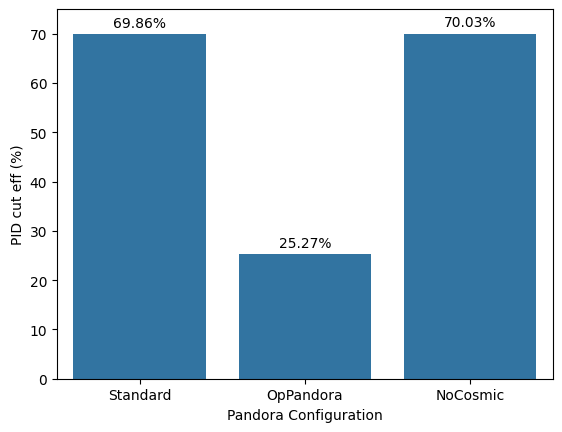

In [15]:
def pid_cut(arr):
    arr['pid_cut'] = (arr.NTracksHI >=1) & (arr.NTracksLI >=1)
    n_signal = len(arr)
    n_pass_pid = sum(arr.pid_cut)
    n_not_pass_pid = sum(~arr.pid_cut)
    
    print(f'Signal passing PID cut: {n_pass_pid} ({100.*n_pass_pid/n_signal:.2f}%)')
    print(f'Signal NOT passing PID cut: {n_not_pass_pid} ({100.*n_not_pass_pid/n_signal:.2f}%)')

    return 100.*n_pass_pid/n_signal

def plot_eff(data, save=False):
    values = []
    
    for k, arr in data.items():
        print(k)
        values.append(pid_cut(arr))
        print('')

    ax = sns.barplot(
        x=data.keys(),
        y=values
    )
    ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=3)
    plt.xlabel("Pandora Configuration")
    plt.ylabel("PID cut eff (%)")
    plt.ylim(0,75)

    if save:
        plt.savefig(
            "./plots/04_efficiencies.png",
            dpi=300,
            bbox_inches="tight"
        )

    plt.show()

plot_eff(data, True)

## Pfp exploration

/tmp/ipykernel_2470/2544644445.py:40: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(title=label, loc='upper right')
/tmp/ipykernel_2470/2544644445.py:40: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(title=label, loc='upper right')
/tmp/ipykernel_2470/2544644445.py:40: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(title=label, loc='upper right')
/tmp/ipykernel_2470/2544644445.py:71: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(title=label, loc='upper 

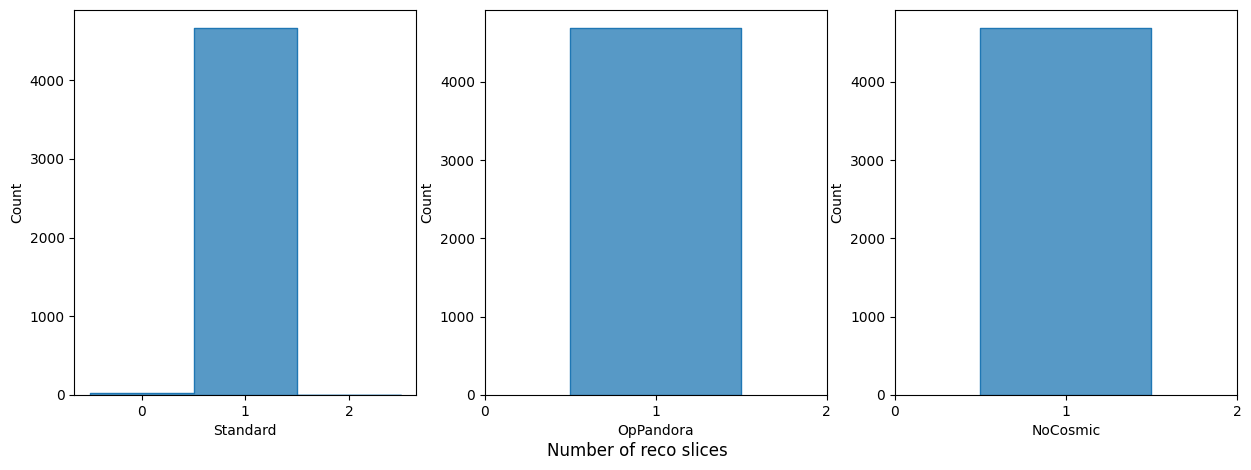

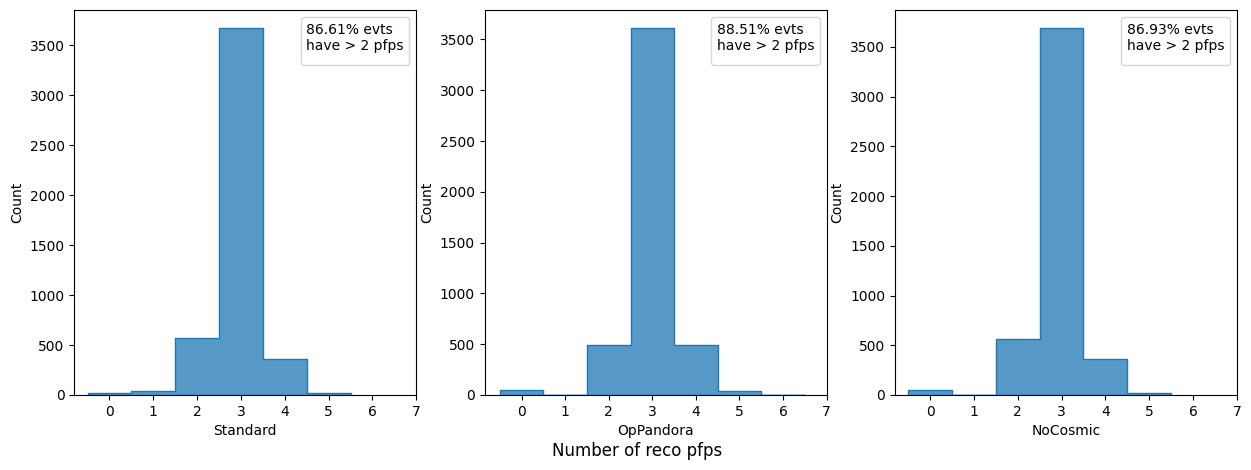

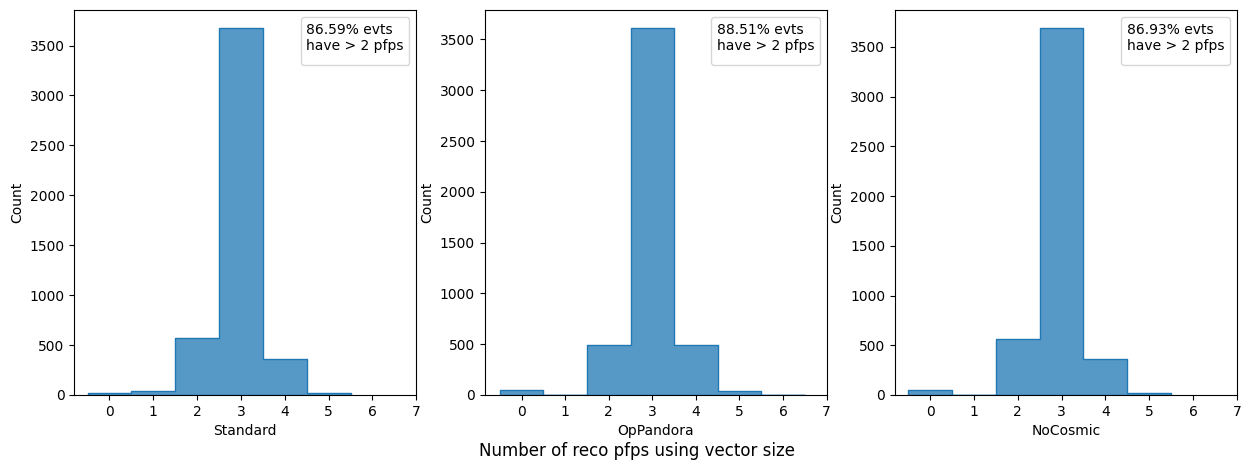

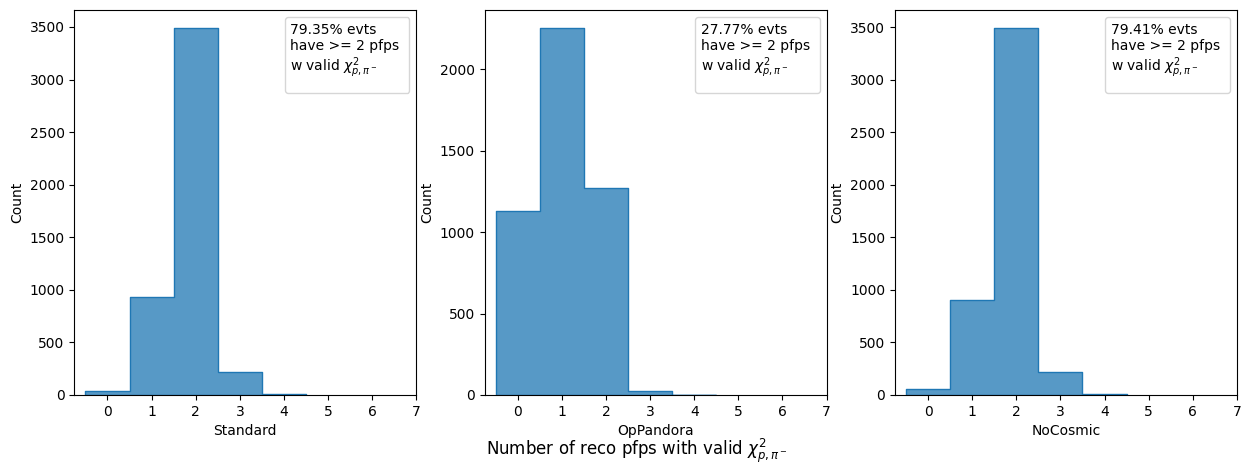

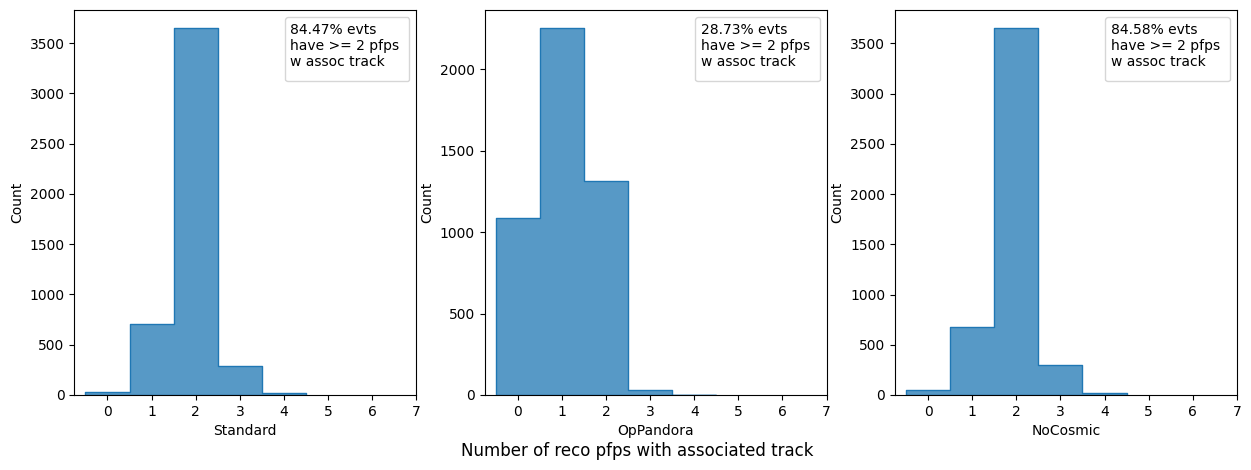

In [33]:
def plot_n_slices(data, save=False):
    fig, axes = plt.subplots(1, 3, figsize=(15,5))
    bins = np.arange(0,4,1)

    for ax, (k, arr) in zip(axes, data.items()):
        sns.histplot(arr.NSlices,
                     bins=bins, 
                     discrete=True,
                     element="step",
                     ax = ax)
        ax.set_xticks(range(0,3))
        ax.set_xlabel(k)
    fig.supxlabel("Number of reco slices", y=-0.02)

    if save:
        fig.savefig(
            "./plots/04_n_slices.png",
            dpi=300,
            bbox_inches="tight"
        )


def plot_n_pfps(data, save=False):
    fig, axes = plt.subplots(1, 3, figsize=(15,5))
    bins = np.arange(0,4,1)

    for ax, (k, arr) in zip(axes, data.items()):

        n_get_2 = sum(arr.NPFPsTotal > 2)
        label = f'{100.*n_get_2/len(arr):.2f}% evts \nhave > 2 pfps'
        #ax.plot([], [], ' ', label=label)
    
        sns.histplot(arr.NPFPsTotal,
                     bins=bins, 
                     discrete=True,
                     element="step",
                     ax = ax)
        ax.set_xticks(range(0,8))
        ax.set_xlabel(k)
        ax.legend(title=label, loc='upper right')
        #ax.legend()
        
    fig.supxlabel("Number of reco pfps", y=-0.02)

    if save:
        fig.savefig(
            "./plots/04_n_pfps.png",
            dpi=300,
            bbox_inches="tight"
        )

def plot_len_pfp_vec(data, save=False):
    fig, axes = plt.subplots(1, 3, figsize=(15,5))
    bins = np.arange(0,4,1)

    for ax, (k, arr) in zip(axes, data.items()):

        n_pfp = ak.num(arr.slc_pfp_id, axis=1)

        n_get_2 = sum(n_pfp > 2)
        label = f'{100.*n_get_2/len(n_pfp):.2f}% evts \nhave > 2 pfps'
        #ax.plot([], [], ' ', label=label)
    
        sns.histplot(n_pfp,
                     bins=bins, 
                     discrete=True,
                     element="step",
                     ax = ax)
        ax.set_xticks(range(0,8))
        ax.set_xlabel(k)
        ax.legend(title=label, loc='upper right')
        #ax.legend()
        
    fig.supxlabel("Number of reco pfps using vector size", y=-0.02)

    if save:
        fig.savefig(
            "./plots/04_n_pfps.png",
            dpi=300,
            bbox_inches="tight"
        )
        

def plot_n_valid_pfps(data, save=False):
    fig, axes = plt.subplots(1, 3, figsize=(15,5))
    bins = np.arange(0,4,1)

    for ax, (k, arr) in zip(axes, data.items()):

        valid_pfp = ((arr.slc_pfp_chi2_proton > 0)
            & (arr.slc_pfp_chi2_pion > 0))

        n_pfp = ak.num(arr.slc_pfp_id[valid_pfp], axis=1)

        n_get_2 = sum(n_pfp >= 2)
        label = f'{100.*n_get_2/len(arr):.2f}% evts \nhave >= 2 pfps \nw valid ' + r'$\chi^2_{p,\pi^-}$'
        #ax.plot([], [], ' ', label=label)
    
        sns.histplot(n_pfp,
                     bins=bins, 
                     discrete=True,
                     element="step",
                     ax = ax)
        ax.set_xticks(range(0,8))
        ax.set_xlabel(k)
        ax.legend(title=label, loc='upper right');
        #ax.legend()
        
    fig.supxlabel(r"Number of reco pfps with valid $\chi^2_{p,\pi^-}$", y=-0.03)

    if save:
        fig.savefig(
            "./plots/04_n_valid_pfps.png",
            dpi=300,
            bbox_inches="tight"
        )


def plot_n_long_pfps(data, save=False):
    fig, axes = plt.subplots(1, 3, figsize=(15,5))
    bins = np.arange(0,4,1)

    for ax, (k, arr) in zip(axes, data.items()):

        min_len = 0

        long_pfp = (arr.slc_pfp_track_length > min_len)

        n_pfp = ak.num(arr.slc_pfp_id[long_pfp], axis=1)

        n_get_2 = sum(n_pfp >= 2)
        label = f'{100.*n_get_2/len(arr):.2f}% evts \nhave >= 2 pfps \nw assoc track'
        #ax.plot([], [], ' ', label=label)
    
        sns.histplot(n_pfp,
                     bins=bins, 
                     discrete=True,
                     element="step",
                     ax = ax)
        ax.set_xticks(range(0,8))
        ax.legend(title=label, loc='upper right');
        #ax.legend()
        ax.set_xlabel(k)
        
    fig.supxlabel(f"Number of reco pfps with associated track", y=-0.02)

    if save:
        fig.savefig(
            "./plots/04_n_pfps_w_trk.png",
            dpi=300,
            bbox_inches="tight"
        )
    


plot_n_slices(data)
plot_n_pfps(data)
plot_len_pfp_vec(data)
plot_n_valid_pfps(data)
plot_n_long_pfps(data)

In [19]:
nocsmc_arr.fields

['RunID',
 'SubRunID',
 'EventID',
 'NSlices',
 'NPFPsTotal',
 'NTracksHI',
 'NTracksLI',
 'InvariantMass',
 'slc_pfp_id',
 'slc_pfp_mother',
 'slc_pfp_is_primary',
 'slc_pfp_track_score',
 'slc_pfp_track_length',
 'slc_pfp_track_theta',
 'slc_pfp_track_phi',
 'slc_pfp_track_start_x',
 'slc_pfp_track_start_y',
 'slc_pfp_track_start_z',
 'slc_pfp_track_end_x',
 'slc_pfp_track_end_y',
 'slc_pfp_track_end_z',
 'slc_pfp_track_dir_x',
 'slc_pfp_track_dir_y',
 'slc_pfp_track_dir_z',
 'slc_pfp_track_kin_energy',
 'slc_pfp_chi2_muon',
 'slc_pfp_chi2_proton',
 'slc_pfp_chi2_pion',
 'slc_pfp_comp',
 'slc_pfp_pur',
 'slc_pfp_true_id',
 'slc_pfp_true_pdg',
 'slc_pfp_true_mother',
 'slc_pfp_true_start_x',
 'slc_pfp_true_start_y',
 'slc_pfp_true_start_z',
 'slc_pfp_true_end_x',
 'slc_pfp_true_end_y',
 'slc_pfp_true_end_z',
 'slc_pfp_true_mass',
 'slc_pfp_true_e0',
 'slc_pfp_true_ef',
 'slc_pfp_true_tl',
 'slc_pfp_true_p0_x',
 'slc_pfp_true_p0_y',
 'slc_pfp_true_p0_z',
 'slc_pfp_true_pf_x',
 'slc_pfp

In [26]:
no_pfps_mask = (nocsmc_arr.NPFPsTotal == 3)
nocsmc_arr[no_pfps_mask].slc_pfp_true_pdg

<Array [[-1, -211, 2212], ..., [-1, 2212, -211]] type='3686 * var * int32'>

In [9]:
mask = (op_arr.slc_pfp_chi2_muon < -900)

op_arr.slc_pfp_track_length[mask]

<Array [[-999], [-999, ...], ..., [-999, -999]] type='4682 * var * float64'>

AttributeError: no field named 'items'

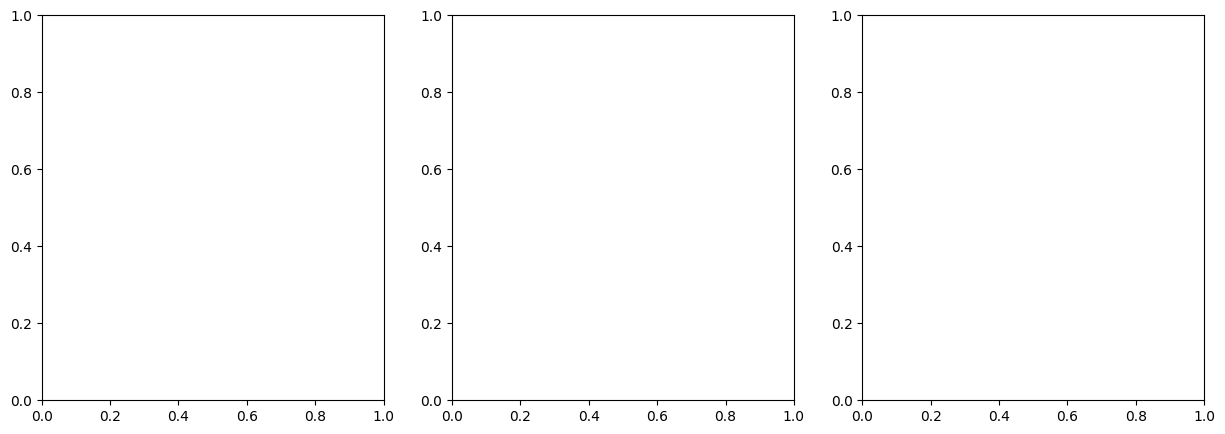

In [10]:
plot_n_slices(std_arr)
plot_n_slices(op_arr)
plot_n_slices(nocsmc_arr)

In [ ]:
valid_pfp = ((s_pid_arr.slc_pfp_track_score > 0)
            & (s_pid_arr.slc_pfp_chi2_proton > 0)
            & (s_pid_arr.slc_pfp_chi2_pion > 0))

n_pfp = ak.num(s_pid_arr.slc_pfp_id[valid_pfp], axis=1)

bins = np.arange(0,6,1)
sns.histplot(n_pfp,
             bins=bins, 
             discrete=True,
             element="step",)

n_get_2 = sum(n_pfp >= 2)
print(f'Signal with more than 2 pfps: {n_get_2} ({100.*n_get_2/n_signal:.2f}%)')

In [ ]:
proton_mask = (s_pid_arr.slc_pfp_true_pdg == 2212)
pion_mask = (s_pid_arr.slc_pfp_true_pdg == -211)

proton_chi2p = ak.flatten(s_pid_arr.slc_pfp_chi2_proton[valid_pfp & proton_mask])
proton_chi2pi = ak.flatten(s_pid_arr.slc_pfp_chi2_pion[valid_pfp & proton_mask])
pion_chi2p = ak.flatten(s_pid_arr.slc_pfp_chi2_proton[valid_pfp & pion_mask])
pion_chi2pi = ak.flatten(s_pid_arr.slc_pfp_chi2_pion[valid_pfp & pion_mask])

In [ ]:
sns.histplot(
    x=proton_chi2pi,
    y=proton_chi2p,
    bins=50,)
plt.grid(True)
plt.title('Protons')
plt.xlabel('Chi2 pion')
plt.ylabel('Chi2 proton')
plt.plot([0, 100], [0, 100], "--", c='red')
plt.show()

plt.figure()
sns.histplot(
    x=pion_chi2pi,
    y=pion_chi2p,
    bins=50,)
plt.grid(True)
plt.title('Pions')
plt.xlabel('Chi2 pion')
plt.ylabel('Chi2 proton')
plt.plot([0, 200], [0, 200], "--", c='red')
plt.show()

In [ ]:
n_pion = len(pion_chi2pi)
n_proton = len(proton_chi2pi)

n_reco_pion = sum(pion_chi2pi < pion_chi2p)
n_reco_proton = sum(proton_chi2pi > proton_chi2p)

print(f'True protons reco as protons: {n_reco_proton}/{n_proton} ({100.*n_reco_proton/n_proton:.2f}%)')
print(f'True pions reco as pions: {n_reco_pion}/{n_pion} ({100.*n_reco_pion/n_pion:.2f}%)')

In [ ]:
def get_proton_variable(arr, var, mask):
    filtered_arr = s_pid_arr[var][mask]
    cleaning_mask = ak.any(mask, axis=1)
    return ak.flatten(filtered_arr[cleaning_mask])

In [ ]:
wrong_protons = (s_pid_arr.slc_pfp_chi2_proton) > (s_pid_arr.slc_pfp_chi2_pion)
ine_mask = (s_pid_arr.slc_pfp_true_end_process == 'protonInelastic')

wr_p_endp = get_proton_variable(s_pid_arr, 'slc_pfp_true_end_process', valid_pfp & proton_mask & wrong_protons)
wr_p_tl = get_proton_variable(s_pid_arr, 'slc_pfp_true_tl', valid_pfp & proton_mask & wrong_protons)

wr_ine_p_tl = get_proton_variable(s_pid_arr, 'slc_pfp_true_tl', valid_pfp & proton_mask & wrong_protons & ine_mask)
wr_noine_p_tl = get_proton_variable(s_pid_arr, 'slc_pfp_true_tl', valid_pfp & proton_mask & wrong_protons & ~ine_mask)

sns.histplot(wr_p_endp)

plt.figure()
sns.histplot(wr_p_tl,
            bins=np.linspace(0,30,30),
            element='step')
plt.xlabel('Proton track length [cm]')

plt.figure()
sns.histplot(wr_ine_p_tl,
            bins=np.linspace(0,30,30),
            element='step')
plt.xlabel('Inelastic proton track length [cm]')

plt.figure()
sns.histplot(wr_noine_p_tl,
            bins=np.linspace(0,30,30),
            element='step')
plt.xlabel('No inelastic proton track length [cm]')

In [ ]:

wrong_protons = (s_pid_arr.slc_pfp_chi2_proton) > (s_pid_arr.slc_pfp_chi2_pion)

arr = s_pid_arr.slc_pfp_true_end_process[valid_pfp & proton_mask & wrong_protons]
mask = ak.any(valid_pfp & proton_mask & wrong_protons, axis=1)

sns.histplot(ak.flatten(arr[mask]))
#hIoni is not inelastic proton

slc_pfp_true_tl

In [ ]:
wrong_protons

### New cut?

In [ ]:
pfp_chi2p = s_pid_arr.slc_pfp_chi2_proton#[valid_pfp]
pfp_chi2pi = s_pid_arr.slc_pfp_chi2_pion#[valid_pfp]
pfp_chi2muon = s_pid_arr.slc_pfp_chi2_muon#[valid_pfp]

pfp_chi2_li = (pfp_chi2pi + pfp_chi2muon)/2

In [ ]:
pid_cut = ak.any(pfp_chi2pi < pfp_chi2p, axis=1) & ak.any(pfp_chi2pi > pfp_chi2p, axis=1)
pid_cut_original = ak.any(pfp_chi2_li < pfp_chi2p, axis=1) & ak.any(pfp_chi2_li > pfp_chi2p, axis=1)

In [ ]:
n_signal_pid_cut = sum(pid_cut)
n_signal_pid_cut_original = sum(pid_cut_original)

print(f'Signal passing new pid cut: {n_signal_pid_cut} ({100.*n_signal_pid_cut/n_signal:.2f}%)')
print(f'Signal passing new pid cut: {n_signal_pid_cut_original} ({100.*n_signal_pid_cut_original/n_signal:.2f}%)')

In [ ]:
print(sum(ak.any(pfp_chi2_li < pfp_chi2p, axis=1)))
print(sum(s_pid_arr.NTracksLI >= 1))

In [ ]:
print(sum(ak.any(pfp_chi2_li > pfp_chi2p, axis=1)))
print(sum(s_pid_arr.NTracksHI >= 1))